# **IMPORT LIBRARY**

In [1]:
import os
import kagglehub
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score

C:\Users\DELL\Desktop\shahzaib.model\.venv314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# **LOAD DATASET**

In [2]:
output = 'output'
visual = os.path.join(output, 'visual')
for d in [output, visual]:
  os.makedirs(d, exist_ok=True)
print('Directory berhasil di buat!')

Directory berhasil di buat!


In [3]:
path = kagglehub.dataset_download("laveshjadon/ai-impact-on-students")

In [4]:
data = os.path.join(path, 'ai_student_impact_dataset (1).csv')

In [5]:
df = pd.read_csv(data)

# **TAHAP I EXPLORATORY DATA ANALYSIS**

## *MENAMPILKAN ISI DATASET*

In [6]:
print('='*26)
print('MENAMPILKAN 5 DATA PERTAMA')
print('='*26)
df.head()

MENAMPILKAN 5 DATA PERTAMA


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [7]:
print('='*27)
print('MENAMPILKAN 5 DATA TERAKHIR')
print('='*27)
df.tail()

MENAMPILKAN 5 DATA TERAKHIR


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
49995,149996,Business,Senior,2.899,12.16,Copywriting/Drafting,Beginner,2,False,13.36,2,Allowed_With_Citation,2,3.584,66.16,High
49996,149997,STEM,Senior,2.870,2.51,Copywriting/Drafting,Intermediate,1,False,4.67,3,Actively_Encouraged,3,3.096,81.62,Medium
49997,149998,Business,Senior,3.177,15.87,Summarizing_Reading,Advanced,5,True,3.92,4,Allowed_With_Citation,5,3.605,97.21,High
49998,149999,Business,Junior,3.398,19.91,Debugging/Troubleshooting,Intermediate,5,False,7.10,5,Allowed_With_Citation,3,3.527,84.12,Medium
49999,150000,Arts,Sophomore,3.242,3.30,Copywriting/Drafting,Beginner,1,False,3.93,2,Allowed_With_Citation,6,3.261,76.16,Low


In [8]:
print('='*29)
print('MENAMPILKAN INFORMASI DATASET')
print('='*29)
df.info()

MENAMPILKAN INFORMASI DATASET
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  str    
 2   Year_of_Study               50000 non-null  str    
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  str    
 6   Prompt_Engineering_Skill    50000 non-null  str    
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  str    
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semeste

In [9]:
print('='*29)
print('MENAMPILKAN STATISTIK DATASET')
print('='*29)
df.describe()

MENAMPILKAN STATISTIK DATASET


,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


## *MENAMPILKAN JUMLAH DATA YANG KOSONG DAN DUPLIKASI*

In [10]:
print(f'Jumlah data yang kosong\n{df.isnull().sum()}')

Jumlah data yang kosong
Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64


In [11]:
print(f'Jumlah data yang terduplikasi {df.duplicated().sum()}')

Jumlah data yang terduplikasi 0


## *VISUALISASI*

In [12]:
numerical_cols = df.select_dtypes(include=['number']).columns

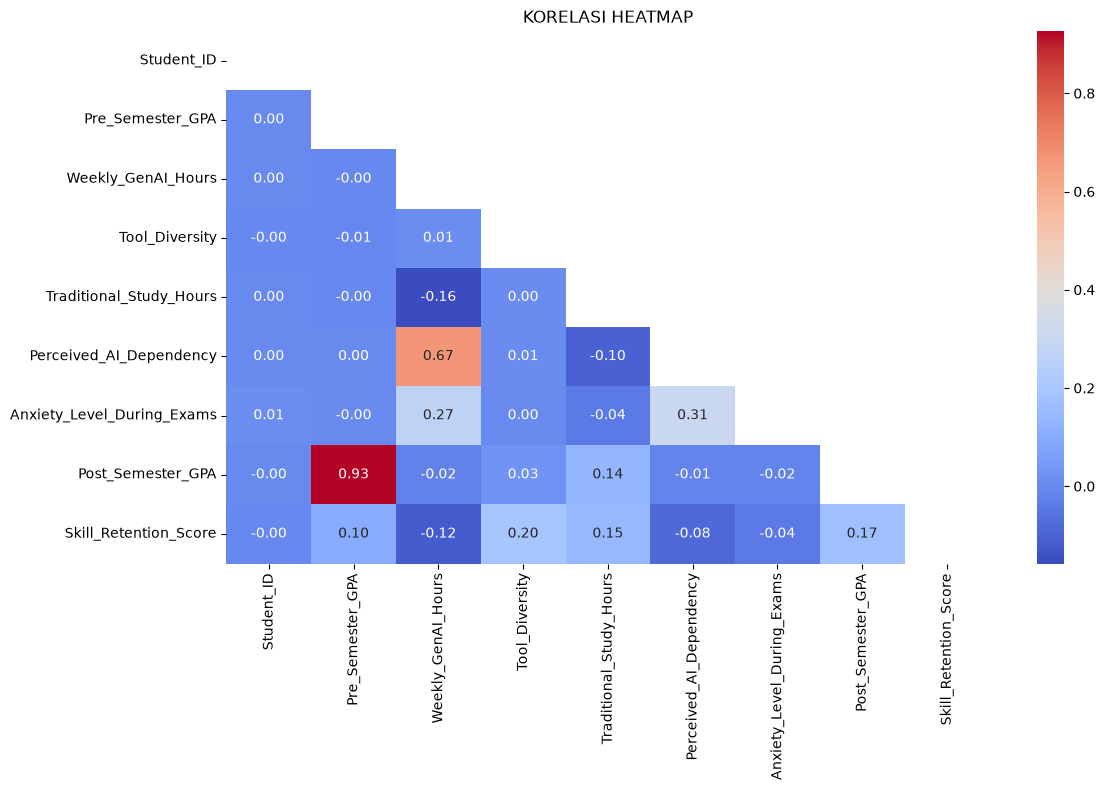

In [13]:
corr = df[numerical_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 8))
sns.heatmap(corr,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            mask=mask)
plt.title('KORELASI HEATMAP')
plt.savefig(f'{visual}/korelasi.png')
plt.tight_layout()
plt.show()

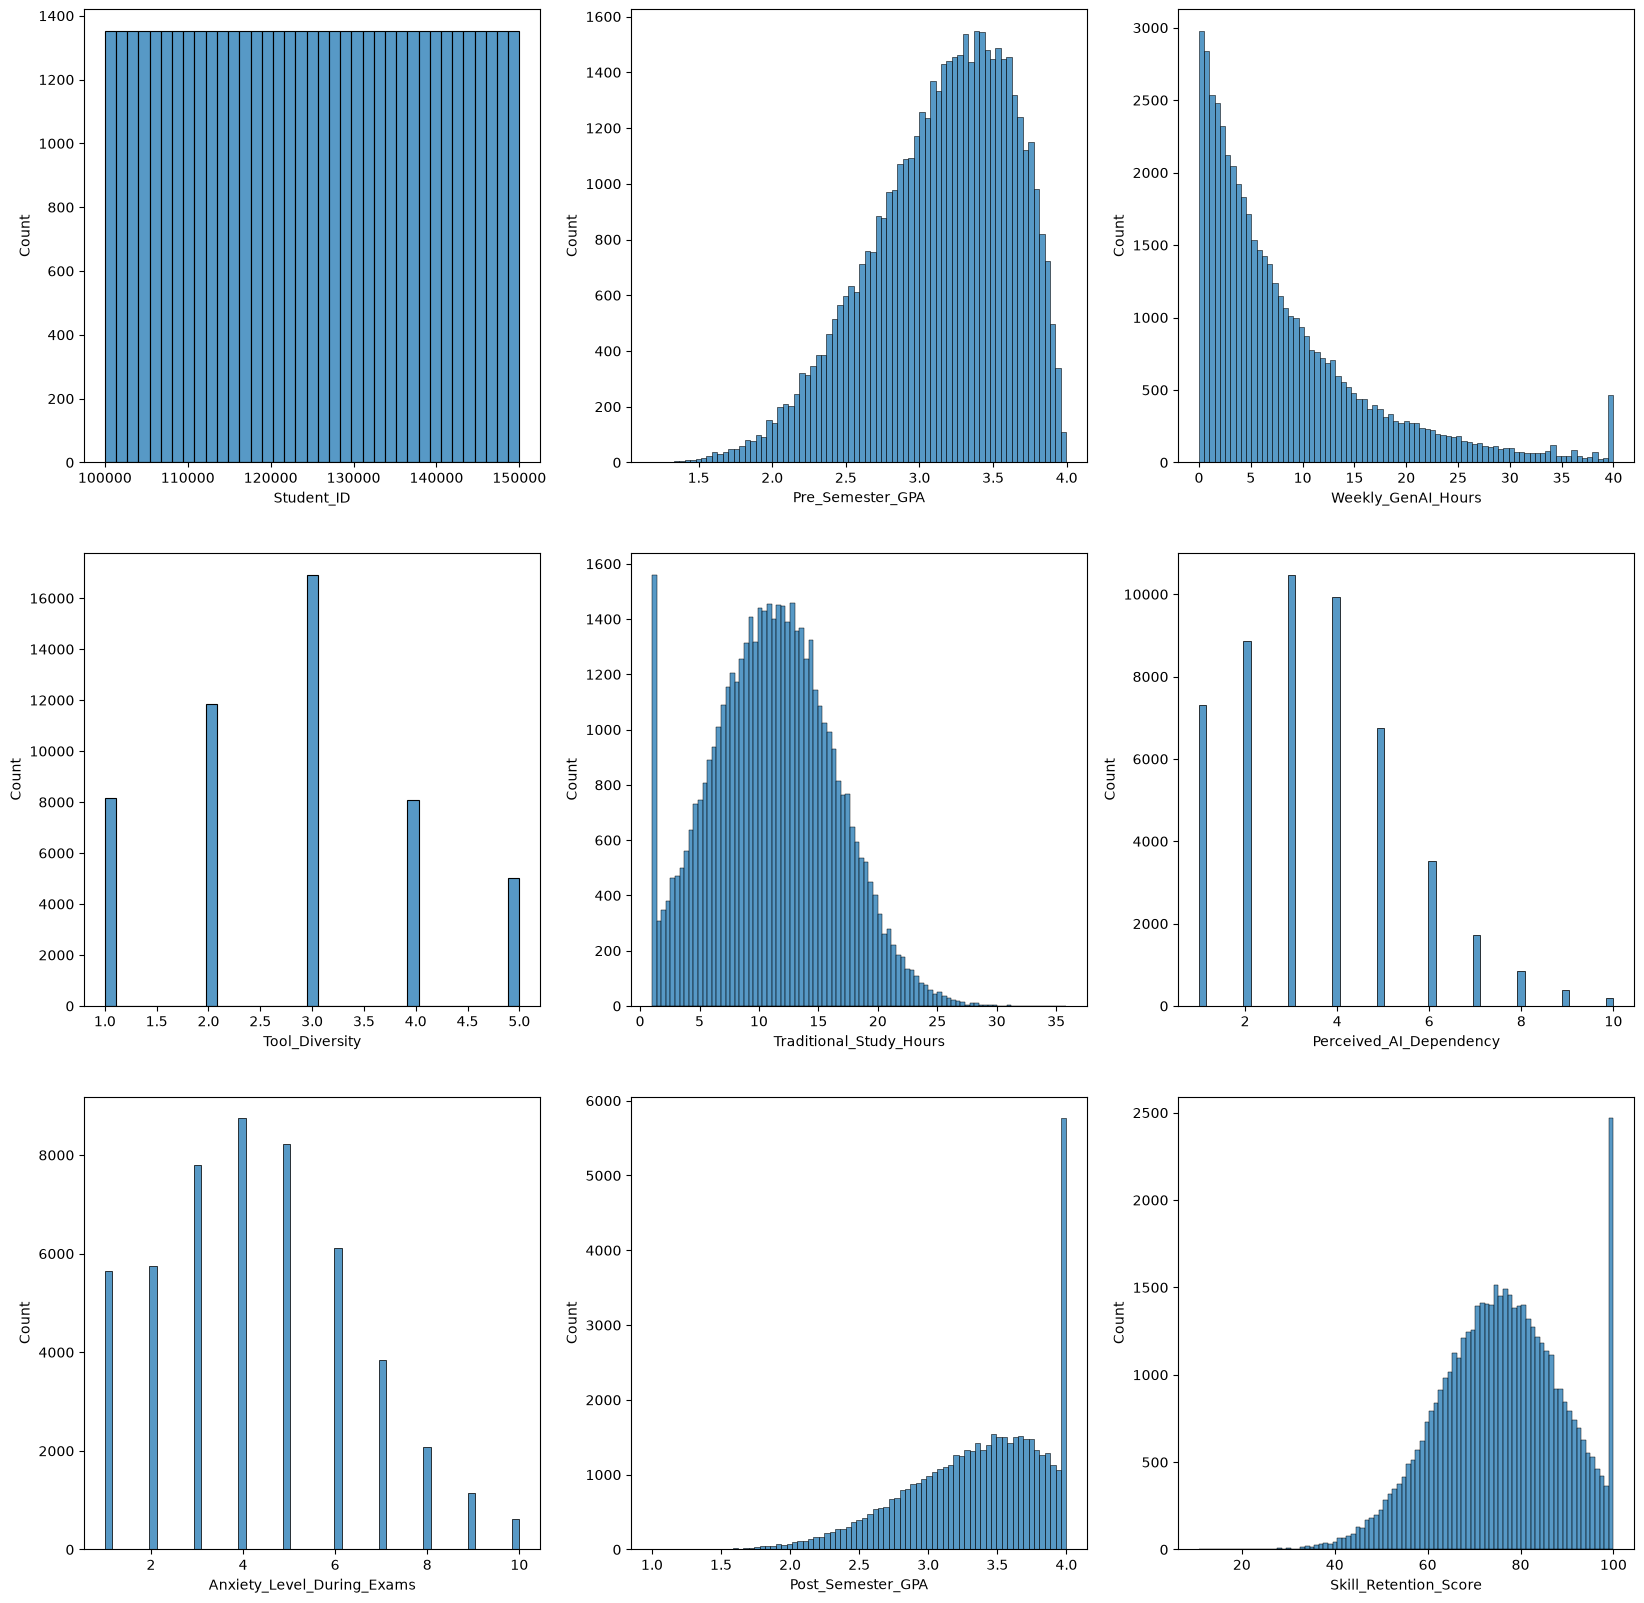

In [14]:
fig, axes = plt.subplots(ncols=3, nrows=3, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
  sns.histplot(x=df[col], ax=axes[i])
plt.savefig(f'{visual}/histogram.png')
plt.show()

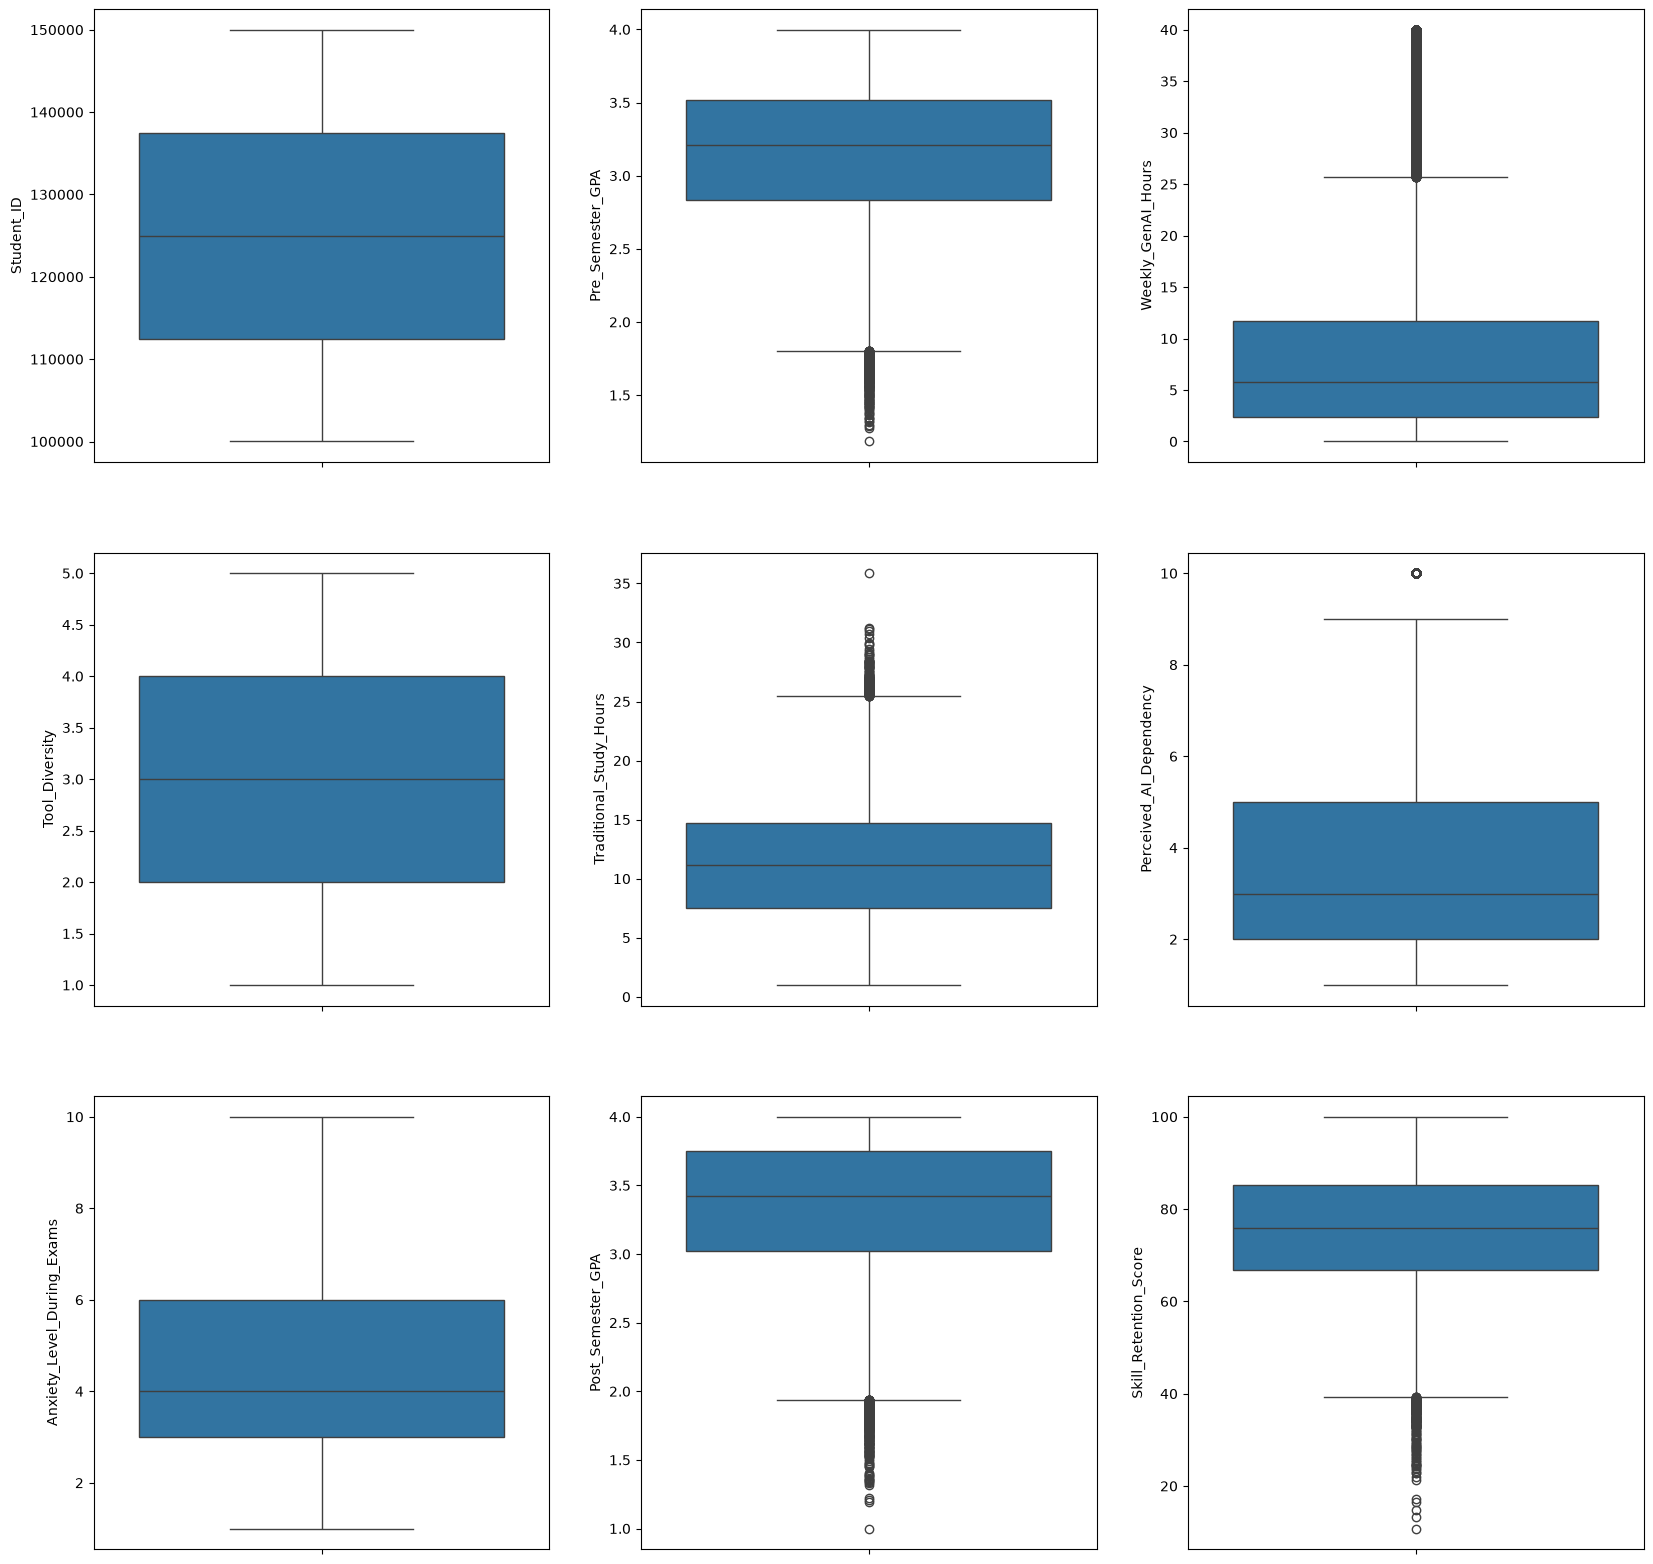

In [15]:
fig, axes = plt.subplots(ncols=3, nrows=3, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
  sns.boxplot(y=df[col], ax=axes[i])
plt.savefig(f'{visual}/boxplot.png')
plt.show()

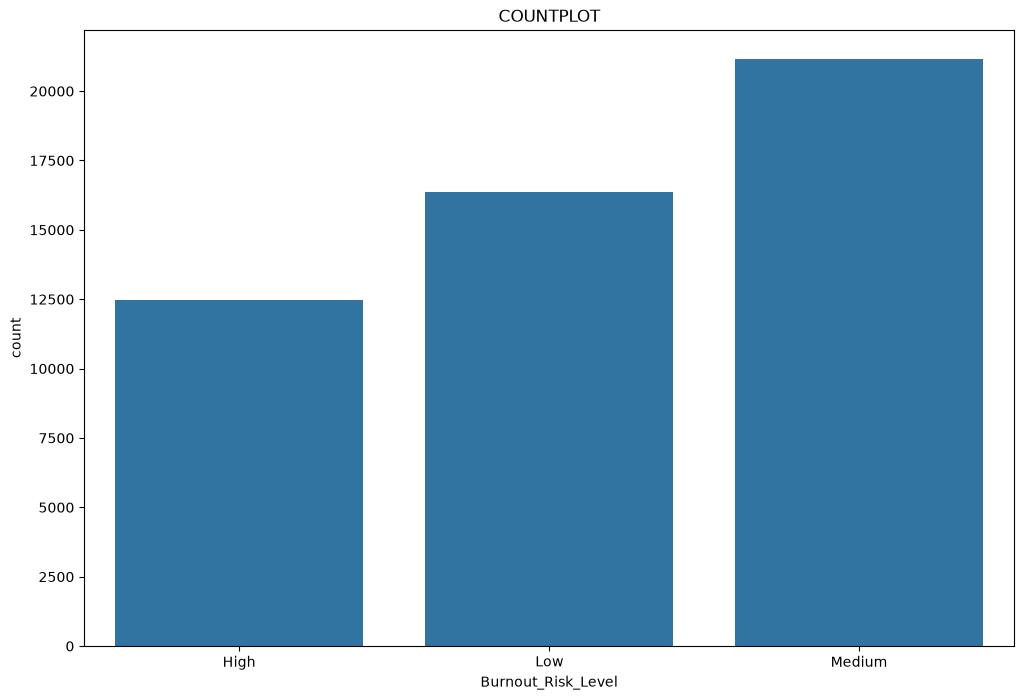

Burnout_Risk_Level
Medium    21144
Low       16369
High      12487
Name: count, dtype: int64

In [16]:
plt.figure(figsize=(12, 8))
sns.countplot(x='Burnout_Risk_Level', data=df)
plt.title('COUNTPLOT')
plt.savefig(f'{visual}/countplot.png')
plt.show()
df['Burnout_Risk_Level'].value_counts()

# **TAHAP II PREPROCESSING**

## *CLEANING*

In [17]:
df = df.drop(columns=[
    'Student_ID',
])

## *FEATURE SELECTION*

In [18]:
X = df.drop(columns=['Burnout_Risk_Level'])
y = df['Burnout_Risk_Level']

## *ENCODER*

In [19]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(include=['number', 'bool']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('numeric', 'passthrough', numeric_cols),
    ]
)
X.head()

C:\Users\DELL\AppData\Local\Temp\ipykernel_7540\2739018608.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
0,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44
1,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39
2,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58
4,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00


## *MEMBAGI DATA TRAINING DAN TESTING*

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# **TAHAP III PROBLEM SOLVING**

In [21]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=350,
        min_samples_leaf=5,
        max_features='sqrt',
        n_jobs=-1,
        random_state=42,
    )),
])

In [22]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Major_Category','Year_of_Study','Pre_Semester_GPA',..., 'Anxiety_Level_During_Exams','Post_Semester_GPA','Skill_Retention_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-speci

In [23]:
y_pred = model.predict(X_test)

In [24]:
test_accuracy = accuracy_score(y_test, y_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
print(f'Test accuracy: {test_accuracy:.3f} ({test_accuracy:.1%})')
print(f'Balanced accuracy: {test_balanced_accuracy:.3f} ({test_balanced_accuracy:.1%})')
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 0.527 (52.7%)
Balanced accuracy: 0.513 (51.3%)
              precision    recall  f1-score   support

        High       0.66      0.46      0.54      2497
         Low       0.54      0.46      0.50      3274
      Medium       0.48      0.62      0.54      4229

    accuracy                           0.53     10000
   macro avg       0.56      0.51      0.53     10000
weighted avg       0.54      0.53      0.53     10000



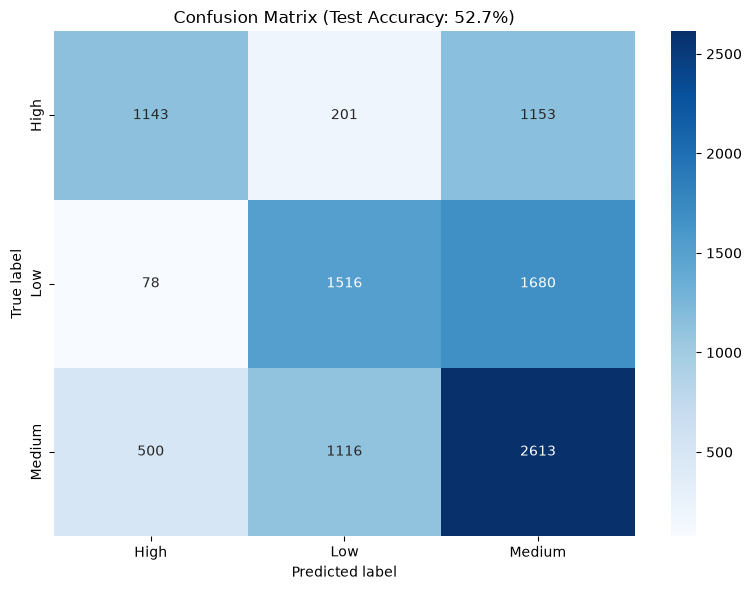

In [25]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    ax=ax,
)
ax.set_title(f'Confusion Matrix (Test Accuracy: {test_accuracy:.1%})')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
plt.tight_layout()
plt.savefig(os.path.join(visual, 'confusion_matrix.png'), dpi=150)
plt.show()

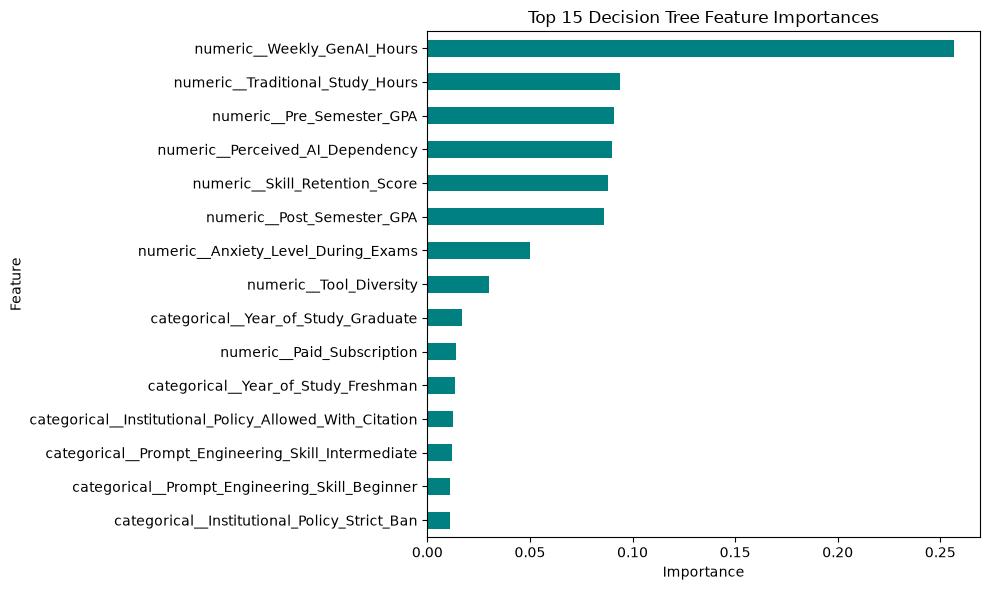

In [26]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
feature_importances = model.named_steps['classifier'].feature_importances_
top_features = pd.Series(feature_importances, index=feature_names).nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
top_features.plot(kind='barh', ax=ax, color='teal')
ax.set_title('Top 15 Decision Tree Feature Importances')
ax.set_xlabel('Importance')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig(os.path.join(visual, 'feature_importance.png'), dpi=150)
plt.show()

# **END OF CODE**